# 02 · Exploration


Goal: understand the business before modelling: growth, seasonality, channels, prices, cancellations and reviews. Charts are saved to `output/figures/` in the same peach and navy style as the Streamlit dashboard (`streamlit_app/`).

In [1]:
# Setup: works from the project root or from notebooks/
import sys
from pathlib import Path
BASE = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
sys.path.append(str(BASE / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from config import *
from theme import *
apply_theme()
make_dirs()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
from load import load_clean
import features as F
clean = load_clean()
b = clean['bookings']

## 1. Yearly KPIs

In [2]:
hotels = clean["hotels"]
cap = {y: sum(((pd.date_range(f"{y}-01-01", f"{y}-12-31") >= h.opening_date).sum()) * h.rooms for h in hotels.itertuples()) for y in range(2021, 2026)}
stay = b[b.status == "Checked-out"]
kpi = b.groupby("year").agg(bookings=("booking_id", "size"), cancel_rate=("is_cancelled", "mean"),
                            room_nights=("room_nights", "sum"), revenue=("room_revenue_eur", "sum"))
kpi["occupancy"] = kpi.room_nights / pd.Series(cap)
kpi["adr"] = stay.groupby("year").apply(lambda d: (d.adr_eur * d.nights).sum() / d.nights.sum())
kpi["revpar"] = kpi.revenue / pd.Series(cap)
kpi["direct_share"] = b.groupby("year").channel_id.apply(lambda s: s.isin(["CH1", "CH2", "CH3"]).mean())
kpi.style.format({"bookings": "{:,.0f}", "cancel_rate": "{:.1%}", "room_nights": "{:,.0f}", "revenue": "€{:,.0f}",
                  "occupancy": "{:.1%}", "adr": "€{:.1f}", "revpar": "€{:.1f}", "direct_share": "{:.1%}"})

,bookings,cancel_rate,room_nights,revenue,occupancy,adr,revpar,direct_share
year,,,,,,,,
2021,"32,136",30.0%,"58,104","€7,766,240",31.6%,€134.9,€42.3,24.9%
2022,"58,376",23.0%,"114,118","€17,856,853",55.5%,€156.9,€86.9,25.6%
2023,"64,775",19.3%,"132,138","€23,098,628",62.2%,€175.6,€108.7,37.0%
2024,"73,538",16.1%,"156,070","€30,116,245",65.4%,€193.3,€126.3,47.7%
2025,"76,473",15.6%,"161,728","€32,646,229",65.9%,€202.2,€133.1,53.6%


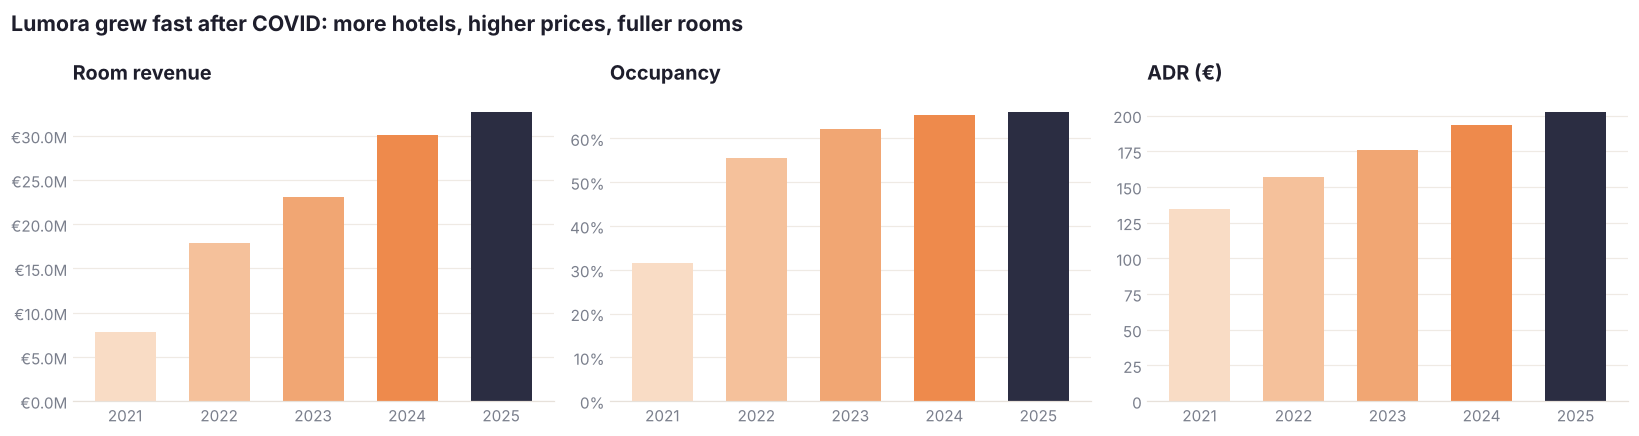

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, ttl, kind in [(axes[0], "revenue", "Room revenue", "eur_m"), (axes[1], "occupancy", "Occupancy", "pct"), (axes[2], "adr", "ADR (€)", None)]:
    ax.bar(kpi.index.astype(str), kpi[col], color=[YEAR_COLORS[y] for y in kpi.index], width=0.65)
    title(ax, ttl)
    if kind: fmt_axis(ax, kind=kind)
fig.suptitle("Lumora grew fast after COVID: more hotels, higher prices, fuller rooms", x=0.01, ha="left", fontsize=14, fontweight="bold", color=TEXT)
plt.tight_layout(); save_fig(fig, "02_yearly_kpis"); plt.show()

## 2. Seasonality and weekly pattern

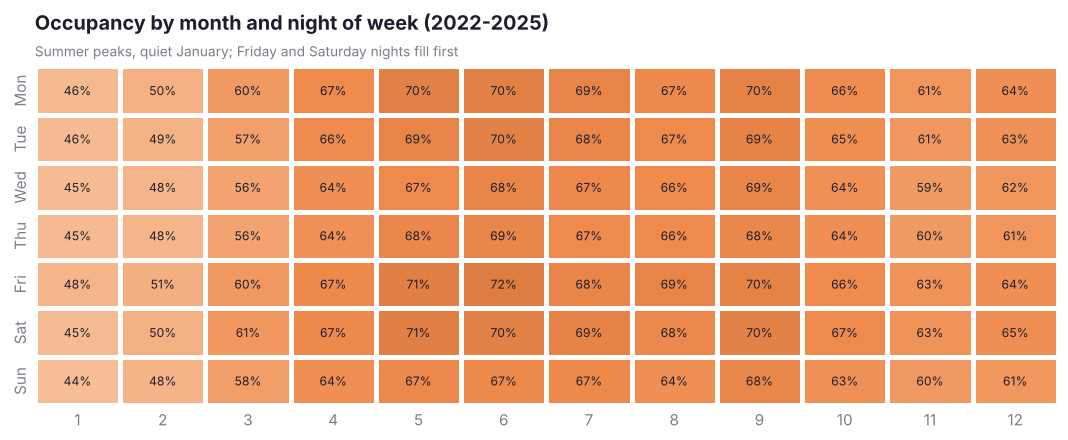

In [4]:
hd = F.hotel_daily(clean)
piv = hd[hd.year >= 2022].pivot_table(index=hd.date.dt.dayofweek, columns="month", values="occupancy", aggfunc="mean")
piv.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(piv, cmap=CMAP_ORANGE, vmin=0, vmax=1, annot=True, fmt=".0%", cbar=False, linewidths=2, linecolor=BG, ax=ax, annot_kws={"color": INK, "fontsize": 8})
title(ax, "Occupancy by month and night of week (2022-2025)", "Summer peaks, quiet January; Friday and Saturday nights fill first")
ax.set_xlabel(""); ax.set_ylabel("")
save_fig(fig, "02_seasonality_heatmap"); plt.show()

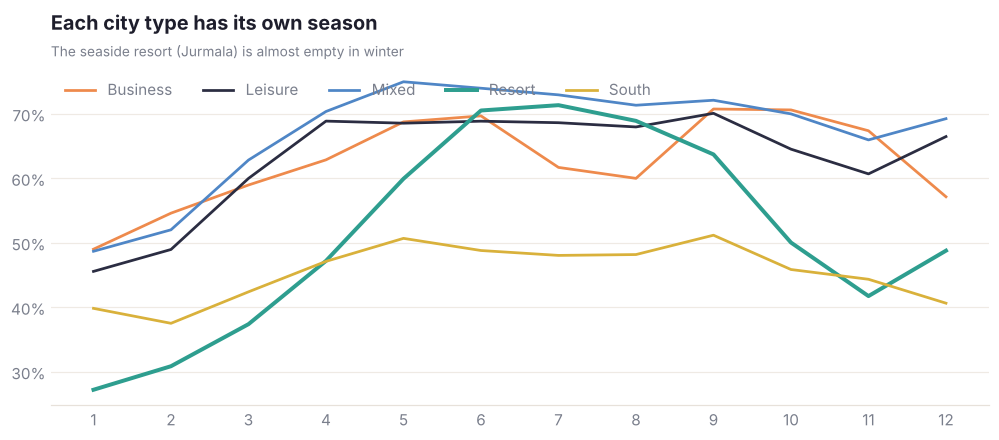

In [5]:
city_type = clean["hotels"].merge(clean["cities"], on="city_id").set_index("hotel_id").city_type
hd["city_type"] = hd.hotel_id.map(city_type)
m = hd[hd.year >= 2022].groupby(["city_type", "month"]).occupancy.mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4))
for i, c in enumerate(m.columns):
    ax.plot(m.index, m[c], lw=2.6 if c == "Resort" else 1.8, color=CATEGORICAL[i], label=c)
ax.set_xticks(range(1, 13)); fmt_axis(ax, kind="pct"); ax.legend(ncol=5, loc="upper left")
title(ax, "Each city type has its own season", "The seaside resort (Jurmala) is almost empty in winter")
save_fig(fig, "02_seasonality_city_type"); plt.show()

## 3. Channels

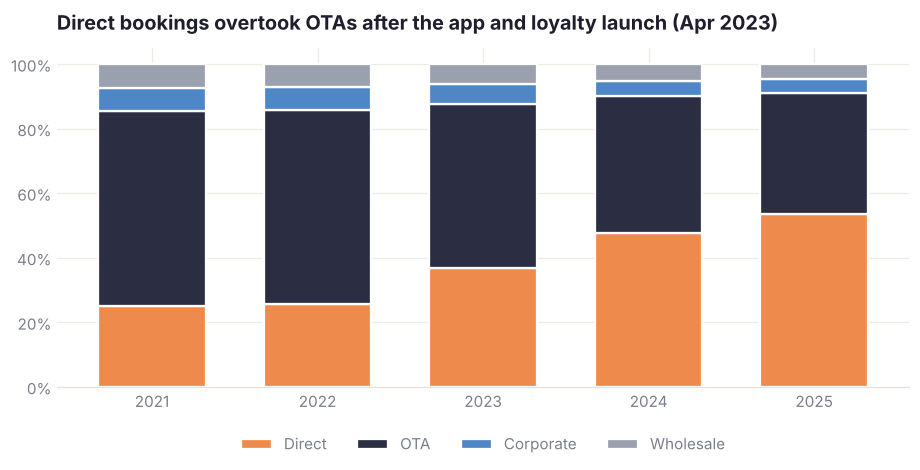

In [6]:
grp = clean["channels"].set_index("channel_id").channel_group
mix = pd.crosstab(b.year, b.channel_id.map(grp), normalize="index")[["Direct", "OTA", "Corporate", "Wholesale"]]
fig, ax = plt.subplots(figsize=(10, 4))
mix.plot(kind="bar", stacked=True, ax=ax, color=[CHANNEL_GROUP_COLORS[c] for c in mix.columns], width=0.65, edgecolor=BG, linewidth=1.5)
fmt_axis(ax, kind="pct"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
title(ax, "Direct bookings overtook OTAs after the app and loyalty launch (Apr 2023)")
save_fig(fig, "02_channel_mix"); plt.show()

## 4. Cancellations

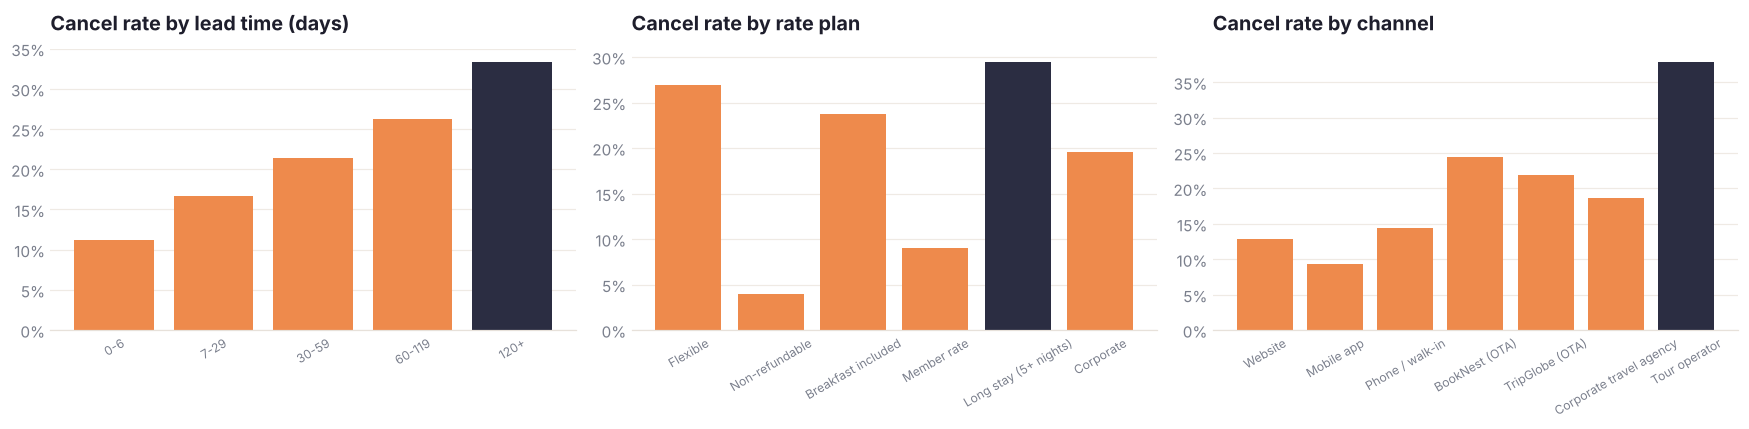

In [7]:
bf = F.booking_features(clean)
bf["lead_bucket"] = pd.cut(bf.lead_time_days, [-1, 6, 29, 59, 119, 999], labels=["0-6", "7-29", "30-59", "60-119", "120+"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, ttl in [(axes[0], "lead_bucket", "by lead time (days)"), (axes[1], "rate_plan_id", "by rate plan"), (axes[2], "channel_id", "by channel")]:
    r = bf.groupby(col, observed=True).is_cancelled.mean()
    if col == "rate_plan_id": r.index = r.index.map(clean["rate_plans"].set_index("rate_plan_id").rate_plan_name)
    if col == "channel_id": r.index = r.index.map(clean["channels"].set_index("channel_id").channel_name)
    ax.bar(r.index.astype(str), r.values, color=[INK_2 if v == r.max() else ORANGE for v in r.values]); fmt_axis(ax, kind="pct"); ax.tick_params(axis="x", rotation=30, labelsize=8)
    title(ax, "Cancel rate " + ttl)
plt.tight_layout(); save_fig(fig, "02_cancellations"); plt.show()

In [8]:
# guests who cancelled before cancel again
bf.groupby(pd.cut(bf.prev_cancel_rate, [-0.01, 0, 0.5, 1], labels=["never", "some", "always"]), observed=True).is_cancelled.agg(["mean", "size"])

,mean,size
prev_cancel_rate,,
never,0.197,283658
some,0.138,10094
always,0.188,11546


## 5. Price vs competitors

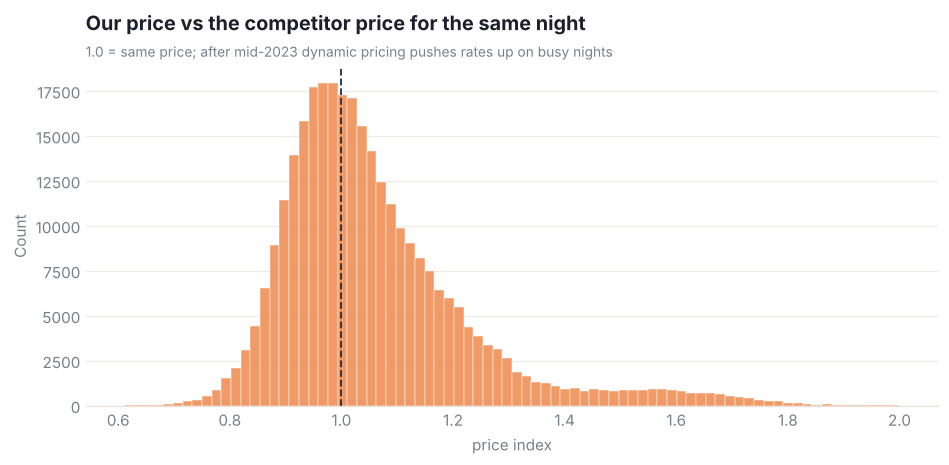

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(bf.price_index.clip(0.5, 2), bins=80, color=ORANGE, alpha=0.85, edgecolor=BG, linewidth=0.3, ax=ax)
ax.axvline(1, color=INK_2, ls="--", lw=1.2)
title(ax, "Our price vs the competitor price for the same night", "1.0 = same price; after mid-2023 dynamic pricing pushes rates up on busy nights")
ax.set_xlabel("price index"); save_fig(fig, "02_price_index"); plt.show()

In [10]:
# price index before / after the revenue management system (1 July 2023)
bf.assign(period=np.where(bf.checkin_date < "2023-07-01", "before RMS", "after RMS")).groupby("period").price_index.describe()[["mean", "std", "25%", "75%"]]

,mean,std,25%,75%
period,,,,
after RMS,1.124,0.190,0.998,1.204
before RMS,0.965,0.075,0.916,1.013


## 6. Reviews

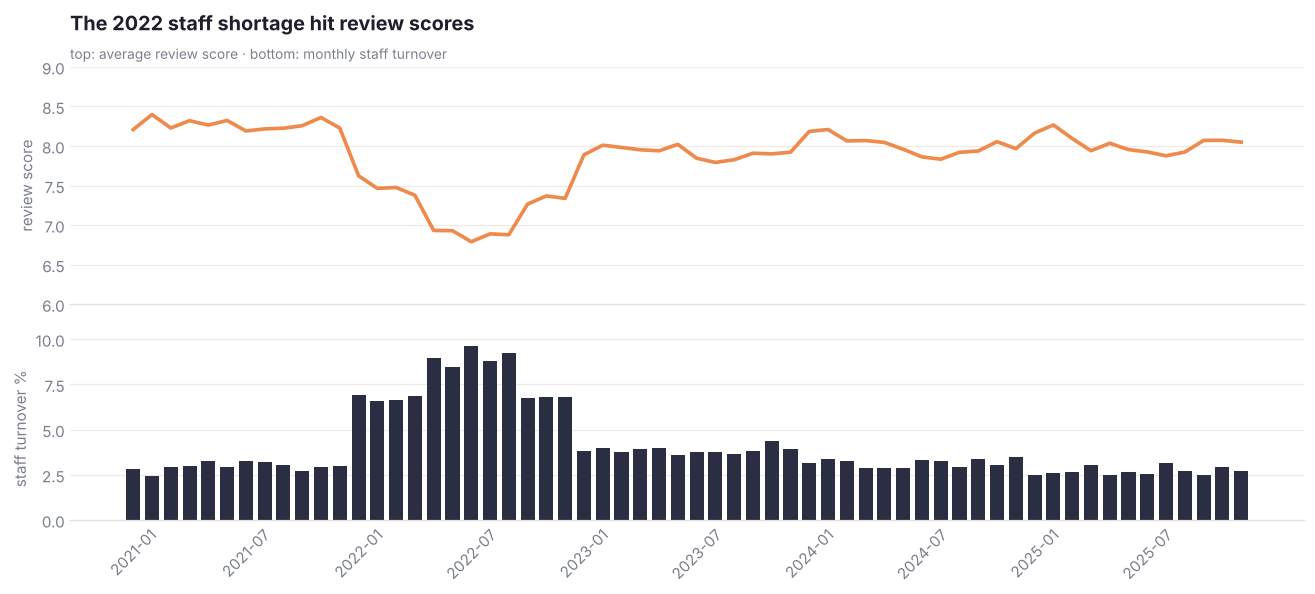

In [11]:
rv = clean["reviews"]
st = clean["staffing_monthly"].groupby("month").staff_turnover_pct.mean()
ms = rv.groupby(rv.review_datetime.dt.to_period("M").astype(str)).overall_score.mean()
ms = ms[ms.index.isin(st.index)]
# two panels that share the month axis (easier to read than two y-axes on one chart)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax.plot(ms.index, ms.values, color=ORANGE, lw=2.4); ax.set_ylim(6, 9); ax.set_ylabel("review score")
ax2.bar(st.index, st.values, color=INK_2, width=0.75); ax2.set_ylabel("staff turnover %")
ax2.set_xticks(range(0, 60, 6)); ax2.tick_params(axis="x", rotation=45)
title(ax, "The 2022 staff shortage hit review scores", "top: average review score · bottom: monthly staff turnover")
plt.tight_layout(); save_fig(fig, "02_reviews_turnover"); plt.show()

In [12]:
rv.groupby("year")[["overall_score", "cleanliness", "staff", "location", "comfort", "value_for_money"]].mean().round(2)

,overall_score,cleanliness,staff,location,comfort,value_for_money
year,,,,,,
2021,8.260,8.270,8.270,8.510,8.300,8.360
2022,7.120,7.260,6.160,8.160,7.410,7.310
2023,7.910,7.960,7.780,8.390,8.040,7.940
2024,8.000,8.040,8.030,8.410,8.110,7.910
2025,8.020,8.060,8.160,8.430,8.130,7.850
2026,7.940,7.960,8.200,8.410,8.030,7.800


## 7. Ancillary spend

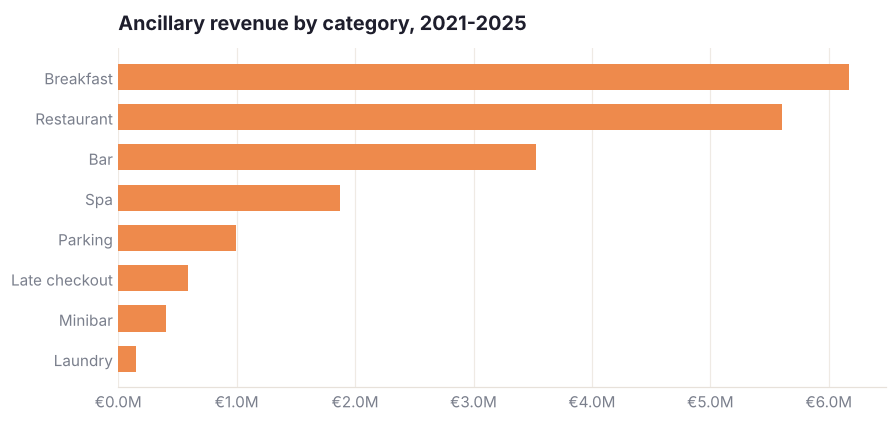

In [13]:
sc = clean["stay_charges"]
sc = sc[sc.is_adjustment == 0]
cat = sc.groupby("category").amount_eur.sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cat.index, cat.values, color=ORANGE, height=0.65); ax.xaxis.set_major_formatter(mtick.FuncFormatter(eur_m)); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
title(ax, "Ancillary revenue by category, 2021-2025")
save_fig(fig, "02_ancillary"); plt.show()

## Key findings
- 2021 is a COVID year (31% occupancy). From 2022 the business grows every year, helped by new hotels and higher prices.
- Strong seasonality by city type, so the forecast needs hotel, month and weekday.
- Cancellations rise with lead time and are much lower for non-refundable rates and loyalty members.
- Prices are set from demand after July 2023, so price and demand are confounded: we need the randomised price test to measure elasticity.
- Review scores fall in 2022 when staff turnover peaks.